In [2]:
import grewpy
from grewpy import Corpus, CorpusDraft, Request
from collections import Counter
import pandas as pd

import sys
sys.path.insert(1, "/Users/madalina/Documents/M2TAL/stage/check_coherent_labels/tod")

import tod.corpus
import tod.outliers
import tod.clustering
import tod.plotting
import tod.dimension_reduction_classic

GREW_PATTERN = "pattern{X[upos<>PUNCT]}"
PATTERNS_TEXT_FILE = "/Users/madalina/Documents/M2TAL/stage/check_coherent_labels/scripts/3. probability_matrix/patterns_all_nodes.txt"
UD_UPOS_LIST = [
    'ADJ', 'ADP', 'ADV', 'AUX', 'CCONJ', 'DET', 'NOUN', 'NUM', 
    'PART', 'PRON', 'PROPN', 'SCONJ', 'SYM', 'VERB', 'INTJ', 'X'
]

connected to port: 52975


In [3]:
def get_inventory_matrix(corpus):
    binary_matrix = {}
    features = corpus._idx2feature
    uposes = set()
    for k, v in features.items():
        if "upos" in v:
            upos = v.split("upos=")[1]
            uposes.add(upos)
    for upos in UD_UPOS_LIST:
        binary_matrix[upos] = 1 if upos in uposes else 0
    return binary_matrix


In [4]:
from sklearn.metrics.pairwise import cosine_similarity
import numpy as np

def get_transition_matrix(corpus):
    similarity_matrix = cosine_similarity(corpus.feature_matrix)
    lang_stats = pd.DataFrame(0.0, index=UD_UPOS_LIST, columns=UD_UPOS_LIST)
    counts = {cat: 0 for cat in UD_UPOS_LIST}

    for idx, lex_unit in corpus._idx2lexunit.items():
        current_category = lex_unit[1]
        if current_category not in UD_UPOS_LIST:
            continue

        counts[current_category] += 1

        threshold_indices = np.where(similarity_matrix[idx] > 0.7)[0]
        high_similarity_indices = sorted(
        [n_idx for n_idx in threshold_indices if n_idx != idx],
        key=lambda x: similarity_matrix[idx][x],
        reverse=True
    )[:20]

        sum_all_weights = sum(similarity_matrix[idx][n_idx] for n_idx in high_similarity_indices)
        
        if sum_all_weights == 0:
            continue

        for n_idx in high_similarity_indices:
            neighbour_category = corpus._idx2lexunit[n_idx][1]
            if neighbour_category in UD_UPOS_LIST and neighbour_category != current_category:
                weight = similarity_matrix[idx][n_idx] / sum_all_weights
                lang_stats.loc[current_category, neighbour_category] += weight

    # # normalised by the nb of occurrences so that a category that occurs more often doesn't have an unfair advantage in the transition matrix
    for cat in UD_UPOS_LIST:
        if counts[cat] > 0:
            lang_stats.loc[cat] = lang_stats.loc[cat] / counts[cat]
        else:
            lang_stats.loc[cat] = np.nan
    
    # so that the rows sum up to 1 like in the heatmaps 
    row_sums = lang_stats.sum(axis=1)
    lang_stats = lang_stats.div(row_sums, axis=0)

    transition_dico = {}
    for src in UD_UPOS_LIST:
        for tgt in UD_UPOS_LIST:
            transition_dico[f"{src}->{tgt}"] = lang_stats.loc[src, tgt]
    return transition_dico

In [5]:
def get_variance_matrix(corpus):
    lex_units = list(corpus._idx2lexunit.values())
    df_lexunits = pd.DataFrame(lex_units, columns=['lemma', 'pos'])
    
    unique_pos = df_lexunits['pos'].unique()
    variance_dico = {}
    for pos in unique_pos:
        idx = df_lexunits[df_lexunits['pos'] == pos].index.tolist()
        if len(idx) > 1:
            category_vectors = corpus.feature_matrix[idx]
            centroid = np.mean(category_vectors, axis=0)
            squared_diffs = np.square(category_vectors - centroid)
            sum_squared_dist = np.sum(squared_diffs, axis=1)
            variance = np.mean(sum_squared_dist)
            variance_dico[f"{pos}_variance"] = variance
        else:
            variance_dico[f"{pos}_variance"] = np.nan
    return variance_dico
    

In [6]:
def process_treebank(path, language_name):

    corpus = tod.corpus.Corpus(
            treebank_path=path,
            grew_pattern=GREW_PATTERN,
            patterns_text_file=PATTERNS_TEXT_FILE,
            use_sud=False,
            matrix_type="coverage",
            excluded_feature_patterns=[r"own"],
            included_feature_patterns=[r"upos=", 
                                        r"position=", 
                                        r"rel_shallow=",
                                        r"Abbr=", 
                                        r"Aspect=",  
                                        r"Animacy=",  
                                        r"Case=",  
                                        r"Clusivity=",  
                                        r"Definite=",  
                                        r"Deixis=", 
                                        r"DeixisRef",  
                                        r"Evident=",  
                                        r"Negation=",
                                        r"Number=",  
                                        r"Gender=",  
                                        r"Degree=",  
                                        r"ExtPos=", 
                                        r"Foreign=", 
                                        r"Mood",  
                                        r"NounClass=",  
                                        r"NumType=",  
                                        r"Person=",  
                                        r"Polarity=", 
                                        r"Polite=",  
                                        r"Poss=",  
                                        r"PronType=",  
                                        r"Reflex=",  
                                        r"Tense=",  
                                        r"Typo=",     
                                        r"VerbForm=",  
                                        r"Voice=",   ])
    # feature_matrix = corpus.feature_matrix
    row_data = {"Language": language_name}
    inventory_matrix = get_inventory_matrix(corpus)
    row_data.update(inventory_matrix)
    transition_matrix = get_transition_matrix(corpus)
    row_data.update(transition_matrix)
    variance_matrix = get_variance_matrix(corpus)
    row_data.update(variance_matrix)
    return row_data


In [7]:
def select_features(master_matrix, main_category, variance_categories):
    selected_columns = []
    if main_category in master_matrix.columns:
        selected_columns.append(main_category)
    
    target_var = f"{main_category}_variance"
    if target_var in master_matrix.columns:
        selected_columns.append(target_var)
    
    for var_cat in variance_categories:
        
        var_col = f"{var_cat}_variance"
        if var_col in master_matrix.columns:
            selected_columns.append(var_col)
    
    relevant_poses = [main_category] + variance_categories

    for col in master_matrix.columns:
        if "->" in col:
            parts = col.split("->")
            if any(part in relevant_poses for part in parts):
                selected_columns.append(col)
    
    unique_cols = list(dict.fromkeys(selected_columns))

    # remove intj, x and sym because they are not really relevant for the typological classification and they add a lot of noise to the heatmap
    for col in unique_cols.copy():
        # Split the column name into its component parts (e.g., 'AUX_variance' -> ['AUX', 'variance'])
        parts = col.replace('->', '_').split('_')
        if any(pos in parts for pos in ["INTJ", "X", "SYM", "SCONJ", "CCONJ", "PROPN"]):
            unique_cols.remove(col)
    
    print(f"Selected columns for {main_category}: {unique_cols}")
    return master_matrix[unique_cols]
                


In [9]:
from tqdm.auto import tqdm
import os
# treebanks_folder = "/Users/madalina/Documents/PHD/code/data/small_test"
# treebanks_folder = "/Users/madalina/Documents/PHD/code/data/single_treebank"
treebanks_folder = "/Users/madalina/Documents/PHD/code/data/test"
treebanks = [t for t in os.listdir(treebanks_folder) if t.startswith("UD_")]

all_language_data = []
for treebank in tqdm(treebanks, desc="Processing treebanks"):
    print(f"Processing {treebank}...")
    full_path = os.path.join(treebanks_folder, treebank)
    try:
        lang_name_list = treebank.split("_")[1:]
        new_s = "_".join(lang_name_list)
        master_matrix_row = process_treebank(full_path, new_s)
        all_language_data.append(master_matrix_row)
    except Exception as e:
        print(f"Failed {treebank}: {e}")

master_df = pd.DataFrame(all_language_data).set_index("Language")
master_df.to_csv("/Users/madalina/Documents/M2TAL/stage/check_coherent_labels/scripts/29. polycategoriality/master_typological_matrix_all_langs.csv")

Processing treebanks:   0%|          | 0/182 [00:00<?, ?it/s]

Processing UD_Akkadian-RIAO...
Processing UD_Central_Kurdish-Mukri...
Processing UD_Armenian-ArmTDP...
Processing UD_Welsh-CCG...
Processing UD_Gheg-GPS...
Processing UD_Old_East_Slavic-TOROT...
Processing UD_Tswana-Popapolelo...
Processing UD_Classical_Armenian-CAVaL...
Processing UD_Azerbaijani-TueCL...
Processing UD_Guajajara-TuDeT...
Processing UD_Nenets-Tundra...
Processing UD_Khoekhoe-KDT...
Processing UD_Bavarian-MaiBaam...
Processing UD_Indonesian-GSD...
Processing UD_Ukrainian-IU...
Processing UD_Dutch-LassySmall...
Processing UD_Egyptian-UJaen...
Processing UD_Polish-PDB...
Processing UD_Kazakh-KTB...
Processing UD_Chintang-CTNTB...
Processing UD_Latin-ITTB...
Processing UD_Madi-Jarawara...
Processing UD_Buryat-BDT...
Processing UD_Kaapor-TuDeT...
Processing UD_Bokota-ChibErgIS...
Processing UD_Estonian-EDT...
Processing UD_Croatian-SET...
Processing UD_Gothic-PROIEL...
Processing UD_Old_French-PROFITEROLE...
Processing UD_Beja-Autogramm...
Processing UD_Middle_French-PROFITE

In [10]:
master_df = pd.DataFrame(all_language_data).set_index("Language")
master_df

,ADJ,ADP,ADV,AUX,CCONJ,DET,NOUN,NUM,PART,PRON,...,PRON_variance,VERB_variance,ADP_variance,DET_variance,ADV_variance,SCONJ_variance,SYM_variance,INTJ_variance,AUX_variance,X_variance
Language,,,,,,,,,,,,,,,,,,,,,
Akkadian-RIAO,1,1,1,0,1,1,1,1,1,1,...,0.016567,0.014995,0.012419,0.020017,0.030410,NaN,NaN,NaN,NaN,NaN
Central_Kurdish-Mukri,1,1,1,0,0,1,1,1,1,1,...,0.010576,0.000524,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Armenian-ArmTDP,1,1,1,1,1,1,1,1,1,1,...,0.008413,0.002899,0.011747,0.006206,0.009757,0.005544,0.033304,0.020691,0.012508,NaN
Welsh-CCG,1,1,1,1,1,1,1,1,1,1,...,0.013948,0.006796,0.007823,0.002773,0.026512,0.008957,0.007890,NaN,0.005871,NaN
Gheg-GPS,1,1,1,1,1,1,1,1,1,1,...,0.013864,0.004221,0.007159,0.009257,0.008023,0.000274,NaN,0.001087,0.014227,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Sicilian-STB,1,1,1,1,1,1,1,1,1,1,...,0.009205,0.003208,0.006117,0.008188,0.008636,0.004184,NaN,NaN,0.020615,NaN
Uyghur-UDT,1,1,1,1,1,1,1,1,1,1,...,0.014174,0.008663,0.015423,0.015150,0.013651,0.007000,NaN,0.005996,0.014412,NaN
Chukchi-HSE,1,1,1,1,1,1,1,1,1,1,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [93]:
languages_to_exclude = ["Central_Kurdish-Mukri", "Tswana-Popapolelo", "Azerbaijani-TueCL", "Madi-Jarawara", "Kaapor-TuDeT", "Assyrian-AS", 
                        "Yupik-SLI", "Warlpiri-UFAL", "Old_Irish-DipSGG", "Apurina-UFPA", "Sinhala-STB", "Komi_Permyak-UH", 
                        "Malayalam-UFAL", "Bengali-BRU", "Neapolitan-RB", "Naga-Suansu", "Skolt_Sami-Giellagas", "Abaza-ATB"]

master_df = master_df.drop(index=languages_to_exclude)

In [94]:
master_df

,ADJ,ADP,ADV,AUX,CCONJ,DET,NOUN,NUM,PART,PRON,...,PRON_variance,VERB_variance,ADP_variance,DET_variance,ADV_variance,SCONJ_variance,SYM_variance,INTJ_variance,AUX_variance,X_variance
Language,,,,,,,,,,,,,,,,,,,,,
Akkadian-RIAO,1,1,1,0,1,1,1,1,1,1,...,0.016567,0.014995,0.012419,0.020017,0.030410,NaN,NaN,NaN,NaN,NaN
Armenian-ArmTDP,1,1,1,1,1,1,1,1,1,1,...,0.008413,0.002899,0.011747,0.006206,0.009757,0.005544,0.033304,0.020691,0.012508,NaN
Welsh-CCG,1,1,1,1,1,1,1,1,1,1,...,0.013948,0.006796,0.007823,0.002773,0.026512,0.008957,0.007890,NaN,0.005871,NaN
Gheg-GPS,1,1,1,1,1,1,1,1,1,1,...,0.013864,0.004221,0.007159,0.009257,0.008023,0.000274,NaN,0.001087,0.014227,NaN
Old_East_Slavic-TOROT,1,1,1,1,1,1,1,1,0,1,...,0.007386,0.004728,0.008648,0.010131,0.007481,0.003973,NaN,0.015135,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Sicilian-STB,1,1,1,1,1,1,1,1,1,1,...,0.009205,0.003208,0.006117,0.008188,0.008636,0.004184,NaN,NaN,0.020615,NaN
Uyghur-UDT,1,1,1,1,1,1,1,1,1,1,...,0.014174,0.008663,0.015423,0.015150,0.013651,0.007000,NaN,0.005996,0.014412,NaN
Chukchi-HSE,1,1,1,1,1,1,1,1,1,1,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [11]:
import numpy as np
import pandas as pd

def manual_gower_matrix(df, cat_cols):
    """
    Computes Gower distance matrix handling NaNs gracefully.
    df: DataFrame with languages as rows
    cat_cols: List of column names to treat as categorical (0/1)
    """
    n = df.shape[0]
    dist_matrix = np.zeros((n, n))
    
    # Pre-calculate ranges for numerical columns to save time
    num_cols = [c for c in df.columns if c not in cat_cols]
    col_ranges = df[num_cols].max() - df[num_cols].min()
    
    # Convert to numpy for speed
    data = df.values
    col_names = list(df.columns)
    cat_indices = [col_names.index(c) for c in cat_cols]
    num_indices = [col_names.index(c) for c in num_cols]

    for i in range(n):
        for j in range(i + 1, n):
            similarities = []
            weights = []
            
            for idx in range(df.shape[1]):
                val_i = data[i, idx]
                val_j = data[j, idx]
                
                # Skip if either is NaN
                if pd.isna(val_i) or pd.isna(val_j):
                    continue
                
                if idx in cat_indices:
                    # Categorical: 1 if same, 0 if different
                    s = 1.0 if val_i == val_j else 0.0
                else:
                    # Numerical: 1 - normalized diff
                    col_range = col_ranges.iloc[num_indices.index(idx)]
                    if col_range == 0:
                        s = 1.0 # They are the same and range is 0
                    else:
                        s = 1.0 - (abs(val_i - val_j) / col_range)
                
                similarities.append(s)
                weights.append(1.0)
            
            if sum(weights) == 0:
                # Total fallback if NO columns overlap
                dist_matrix[i, j] = dist_matrix[j, i] = 1.0
            else:
                sim = sum(similarities) / sum(weights)
                dist_matrix[i, j] = dist_matrix[j, i] = 1.0 - sim
                
    return dist_matrix

# Usage:
# dist_matrix = manual_gower_matrix(filtered_df, cat_cols=['ADJ'])

In [97]:

main_comparison_category = "ADJ"
variance_categories = ["NOUN", "VERB"]

pos_df = select_features(master_df, main_comparison_category, variance_categories)
cat_features_mask = [col == main_comparison_category for col in pos_df.columns]
# pos_df = pos_df.loc[:, pos_df.nunique(dropna=True) > 1]
pos_df = pos_df.dropna(thresh=10, subset=pos_df.columns[1:])
distance_matrix = manual_gower_matrix(pos_df, cat_cols=[main_comparison_category])


Selected columns for ADJ: ['ADJ', 'ADJ_variance', 'NOUN_variance', 'VERB_variance', 'ADJ->ADJ', 'ADJ->ADP', 'ADJ->ADV', 'ADJ->AUX', 'ADJ->DET', 'ADJ->NOUN', 'ADJ->NUM', 'ADJ->PART', 'ADJ->PRON', 'ADJ->VERB', 'ADP->ADJ', 'ADP->NOUN', 'ADP->VERB', 'ADV->ADJ', 'ADV->NOUN', 'ADV->VERB', 'AUX->ADJ', 'AUX->NOUN', 'AUX->VERB', 'DET->ADJ', 'DET->NOUN', 'DET->VERB', 'NOUN->ADJ', 'NOUN->ADP', 'NOUN->ADV', 'NOUN->AUX', 'NOUN->DET', 'NOUN->NOUN', 'NOUN->NUM', 'NOUN->PART', 'NOUN->PRON', 'NOUN->VERB', 'NUM->ADJ', 'NUM->NOUN', 'NUM->VERB', 'PART->ADJ', 'PART->NOUN', 'PART->VERB', 'PRON->ADJ', 'PRON->NOUN', 'PRON->VERB', 'VERB->ADJ', 'VERB->ADP', 'VERB->ADV', 'VERB->AUX', 'VERB->DET', 'VERB->NOUN', 'VERB->NUM', 'VERB->PART', 'VERB->PRON', 'VERB->VERB']


In [71]:
pos_df = select_features(master_df, main_comparison_category, variance_categories)
pos_df = pos_df.dropna(thresh=10, subset=pos_df.columns[1:])
cat_features_mask = [col == main_comparison_category for col in pos_df.columns]
# pos_df = pos_df.loc[:, pos_df.nunique(dropna=True) > 1]
distance_matrix = manual_gower_matrix(pos_df, cat_cols=[main_comparison_category])

Selected columns for ADJ: ['ADJ', 'ADJ_variance', 'NOUN_variance', 'VERB_variance', 'ADJ->ADJ', 'ADJ->ADP', 'ADJ->ADV', 'ADJ->AUX', 'ADJ->DET', 'ADJ->NOUN', 'ADJ->NUM', 'ADJ->PART', 'ADJ->PRON', 'ADJ->VERB', 'ADP->ADJ', 'ADP->NOUN', 'ADP->VERB', 'ADV->ADJ', 'ADV->NOUN', 'ADV->VERB', 'AUX->ADJ', 'AUX->NOUN', 'AUX->VERB', 'DET->ADJ', 'DET->NOUN', 'DET->VERB', 'NOUN->ADJ', 'NOUN->ADP', 'NOUN->ADV', 'NOUN->AUX', 'NOUN->DET', 'NOUN->NOUN', 'NOUN->NUM', 'NOUN->PART', 'NOUN->PRON', 'NOUN->VERB', 'NUM->ADJ', 'NUM->NOUN', 'NUM->VERB', 'PART->ADJ', 'PART->NOUN', 'PART->VERB', 'PRON->ADJ', 'PRON->NOUN', 'PRON->VERB', 'VERB->ADJ', 'VERB->ADP', 'VERB->ADV', 'VERB->AUX', 'VERB->DET', 'VERB->NOUN', 'VERB->NUM', 'VERB->PART', 'VERB->PRON', 'VERB->VERB']


In [98]:
pos_df

,ADJ,ADJ_variance,NOUN_variance,VERB_variance,ADJ->ADJ,ADJ->ADP,ADJ->ADV,ADJ->AUX,ADJ->DET,ADJ->NOUN,...,VERB->ADJ,VERB->ADP,VERB->ADV,VERB->AUX,VERB->DET,VERB->NOUN,VERB->NUM,VERB->PART,VERB->PRON,VERB->VERB
Language,,,,,,,,,,,,,,,,,,,,,
Akkadian-RIAO,1,0.017801,0.023770,0.014995,0.0,0.000000,0.000000,0.000000,0.143506,0.575872,...,0.000000,0.0,0.000000,0.000000,0.000000,0.810904,0.000000,0.0,0.000000,0.0
Armenian-ArmTDP,1,0.009827,0.007460,0.002899,0.0,0.005799,0.003645,0.000000,0.476195,0.116146,...,0.713168,0.0,0.000000,0.000000,0.010226,0.214686,0.010106,0.0,0.010431,0.0
Welsh-CCG,1,0.016754,0.008849,0.006796,0.0,0.193011,0.093642,0.000000,0.043120,0.274908,...,0.015446,0.0,0.000000,0.000000,0.000000,0.984554,0.000000,0.0,0.000000,0.0
Gheg-GPS,1,0.009072,0.007610,0.004221,0.0,0.000000,0.374418,0.000000,0.000000,0.105569,...,0.000000,0.0,0.293855,0.000000,0.000000,0.706145,0.000000,0.0,0.000000,0.0
Old_East_Slavic-TOROT,1,0.009122,0.006959,0.004728,0.0,0.017562,0.056577,0.005440,0.353815,0.250324,...,0.283770,0.0,0.117551,0.004438,0.000000,0.428079,0.008756,0.0,0.026150,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Hebrew-HTB,1,0.010850,0.007115,0.004962,0.0,0.000000,0.042768,0.000000,0.000000,0.090908,...,0.581185,0.0,0.061401,0.000000,0.000000,0.357414,0.000000,0.0,0.000000,0.0
Sicilian-STB,1,0.016057,0.006430,0.003208,0.0,0.294991,0.000000,0.038086,0.490633,0.000000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Uyghur-UDT,1,0.017915,0.012206,0.008663,0.0,0.001661,0.048172,0.006996,0.090835,0.478779,...,0.099707,0.0,0.077943,0.000000,0.000000,0.815930,0.000000,0.0,0.006420,0.0


In [99]:
# You may need to install this: pip install scikit-learn-extra
from sklearn_extra.cluster import KMedoids

# Initialize KMedoids - 'metric' must be 'precomputed'
# n_clusters is a hyperparameter you'll need to tune
pam = KMedoids(n_clusters=5, metric='precomputed', random_state=42)
pam_clusters = pam.fit_predict(distance_matrix)

# You can now use pam_clusters as your 'c' argument in your MDS plot

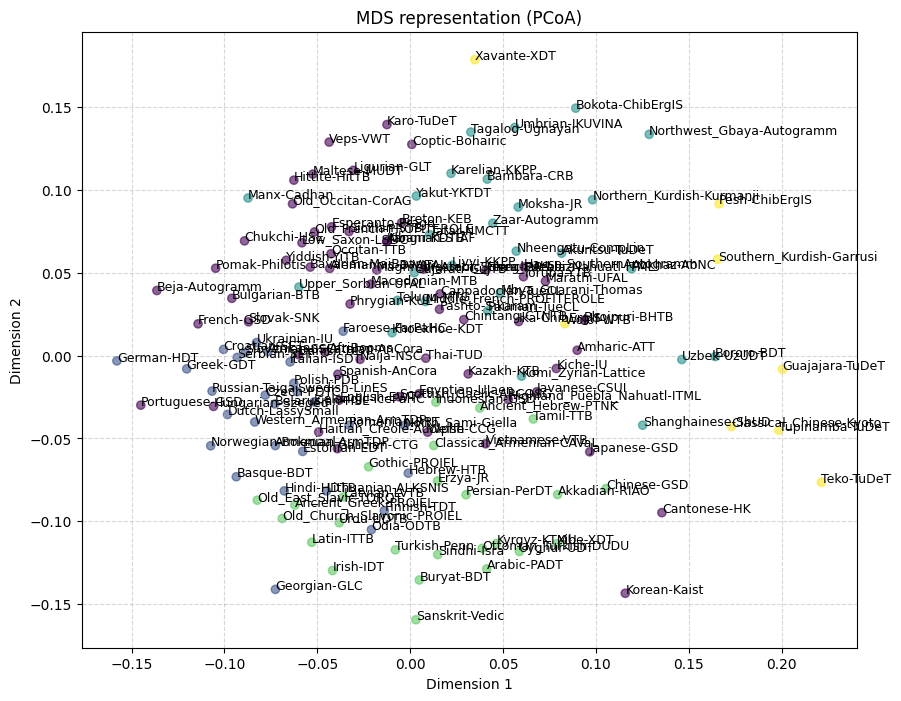

In [100]:
from sklearn.manifold import MDS
import matplotlib.pyplot as plt

# 1. Initialize MDS (MDS with 'precomputed' dissimilarity is PCoA)
mds = MDS(n_components=2, dissimilarity='precomputed', random_state=42)

# 2. Fit and transform the Gower distance matrix
coords = mds.fit_transform(distance_matrix)

# 3. Plot the results
plt.figure(figsize=(10, 8))
plt.scatter(coords[:, 0], coords[:, 1], c=pam_clusters, alpha=0.6)

# Annotate each point with the language name
for i, lang_name in enumerate(pos_df.index):
    plt.annotate(lang_name, (coords[i, 0], coords[i, 1]), fontsize=9)

plt.title("MDS representation (PCoA)")
plt.xlabel("Dimension 1")
plt.ylabel("Dimension 2")
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

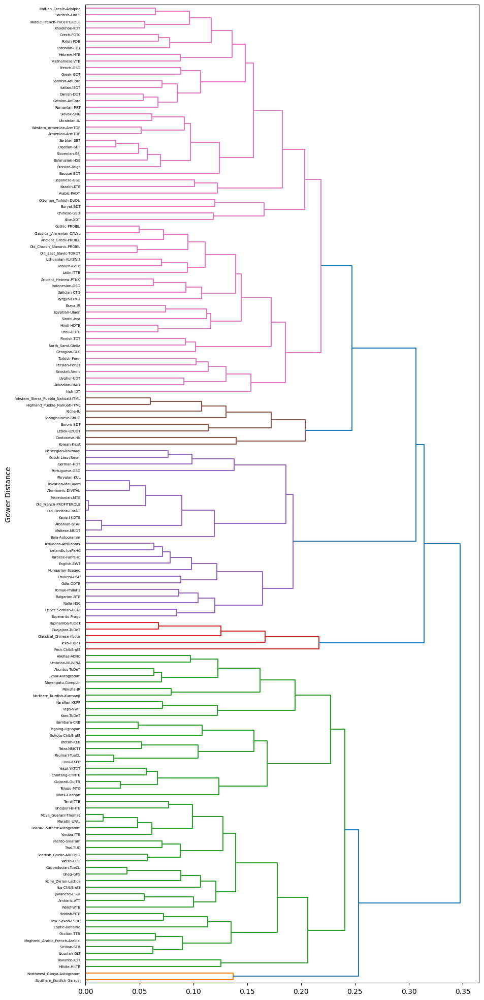

In [114]:
from scipy.cluster.hierarchy import dendrogram, linkage
from scipy.spatial.distance import squareform

# 1. Convert the distance matrix to 'condensed' form for SciPy
# (Ensures the matrix is symmetric and zeros on the diagonal)
condensed_dist = squareform(distance_matrix, force='tovector')

# 2. Perform Linkage (Ward's method is usually best for clusters)
Z = linkage(condensed_dist, method='complete')

# 3. Plot the Dendrogram
plt.figure(figsize=(10, 25))
dendrogram(Z, labels=pos_df.index, leaf_rotation=0, orientation="right", distance_sort='ascending')
# plt.title("Hierarchical Typology of Languages")
plt.ylabel("Gower Distance")
plt.show()

In [105]:
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import linkage, fcluster

def find_optimal_clusters(distance_matrix, max_k=50):

    condensed_dist = squareform(distance_matrix, force='tovector')
    Z = linkage(condensed_dist, method='complete')
    silhouette_scores = []
    for num_clusters in range(2, max_k + 1):
        # Get cluster labels for the current number of clusters
        cluster_labels = fcluster(Z, num_clusters, criterion='maxclust')
        
        # Calculate silhouette score (using the original distance matrix)
        score = silhouette_score(distance_matrix, cluster_labels, metric='precomputed')
        silhouette_scores.append(score)
        print(f"Silhouette Score for {num_clusters} clusters: {score:.4f}")
    optimal_clusters = np.argmax(silhouette_scores) + 2  # +2 because we started from 2 clusters
    print(f"Optimal number of clusters: {optimal_clusters}")
    return optimal_clusters

optimal_k = find_optimal_clusters(distance_matrix, max_k=30)


Silhouette Score for 2 clusters: 0.0917
Silhouette Score for 3 clusters: 0.1159
Silhouette Score for 4 clusters: 0.0703
Silhouette Score for 5 clusters: 0.0712
Silhouette Score for 6 clusters: 0.0865
Silhouette Score for 7 clusters: 0.0678
Silhouette Score for 8 clusters: 0.0604
Silhouette Score for 9 clusters: 0.0631
Silhouette Score for 10 clusters: 0.0639
Silhouette Score for 11 clusters: 0.0649
Silhouette Score for 12 clusters: 0.0673
Silhouette Score for 13 clusters: 0.0722
Silhouette Score for 14 clusters: 0.0776
Silhouette Score for 15 clusters: 0.0743
Silhouette Score for 16 clusters: 0.0715
Silhouette Score for 17 clusters: 0.0670
Silhouette Score for 18 clusters: 0.0749
Silhouette Score for 19 clusters: 0.0884
Silhouette Score for 20 clusters: 0.0924
Silhouette Score for 21 clusters: 0.0946
Silhouette Score for 22 clusters: 0.0930
Silhouette Score for 23 clusters: 0.0922
Silhouette Score for 24 clusters: 0.0937
Silhouette Score for 25 clusters: 0.0980
Silhouette Score for 26 

In [106]:
condensed_dist = squareform(distance_matrix, force='tovector')

# 2. Perform Linkage (Ward's method is usually best for clusters)
Z = linkage(condensed_dist, method='complete')
labels = fcluster(Z, optimal_k, criterion='maxclust')
clusters = {i: [] for i in range(1, optimal_k + 1)}
for i, label in enumerate(labels):
    clusters[label].append(i)

In [111]:
pos_df.index[clusters[3]]

Index(['Akkadian-RIAO', 'Armenian-ArmTDP', 'Old_East_Slavic-TOROT',
       'Classical_Armenian-CAVaL', 'Khoekhoe-KDT', 'Bavarian-MaiBaam',
       'Indonesian-GSD', 'Ukrainian-IU', 'Dutch-LassySmall', 'Egyptian-UJaen',
       'Polish-PDB', 'Kazakh-KTB', 'Latin-ITTB', 'Buryat-BDT', 'Estonian-EDT',
       'Croatian-SET', 'Gothic-PROIEL', 'Old_French-PROFITEROLE',
       'Beja-Autogramm', 'Middle_French-PROFITEROLE', 'Italian-ISDT',
       'North_Sami-Giella', 'Norwegian-Bokmaal', 'Naija-NSC', 'Latvian-LVTB',
       'Xibe-XDT', 'Lithuanian-ALKSNIS', 'Galician-CTG', 'Vietnamese-VTB',
       'Greek-GDT', 'German-HDT', 'Catalan-AnCora', 'English-EWT',
       'Albanian-STAF', 'Swedish-LinES', 'Phrygian-KUL', 'Old_Occitan-CorAG',
       'Erzya-JR', 'Macedonian-MTB', 'Basque-BDT', 'Slovak-SNK', 'Kiche-IU',
       'Russian-Taiga', 'Georgian-GLC', 'Spanish-AnCora', 'Maltese-MUDT',
       'Finnish-TDT', 'Ancient_Hebrew-PTNK', 'Icelandic-IcePaHC', 'Urdu-UDTB',
       'Romanian-RRT', 'Persian-PerDT',

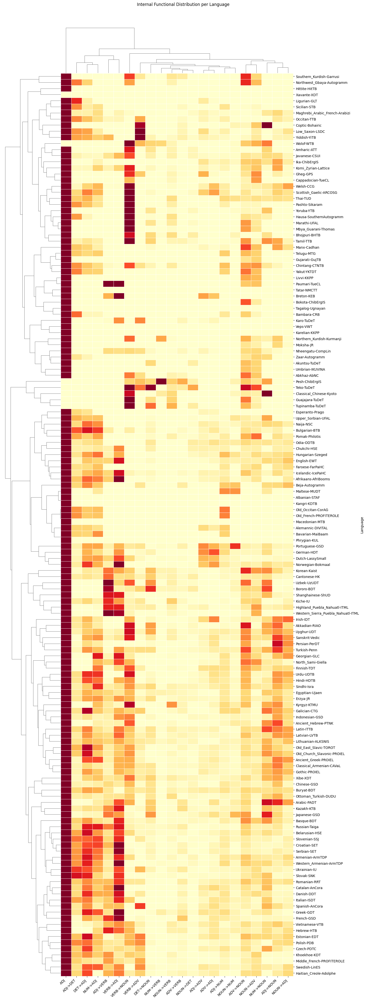

In [148]:
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.preprocessing import Normalizer

def plot_typological_heatmap(df, row_linkage=None, col_linkage=None):
    """
    df: The filtered_df containing the 6 languages and selected features.
    """
    # 1. Handle NaNs: To plot, we usually fill NaNs with 0 or a 'missing' color.
    # For a heatmap, 0 is often best to show the 'absence' of a feature.
    plot_data = df.fillna(0)
    # drop columns with variance in the name
    plot_data = plot_data.loc[:, ~plot_data.columns.str.contains('variance')]
    plot_data = plot_data.loc[:, ~plot_data.columns.str.contains('ADP')]
    plot_data = plot_data.loc[:, ~plot_data.columns.str.contains('AUX')]
    plot_data = plot_data.loc[:, ~plot_data.columns.str.contains('PART')]
    plot_data = plot_data.loc[:, ~plot_data.columns.str.contains('PRON')]
    plot_data = plot_data.loc[:, ~plot_data.columns.str.contains('VERB->DET')]
    plot_data = plot_data.loc[:, ~plot_data.columns.str.contains('VERB->NUM')]
    plot_data = plot_data.loc[:, ~plot_data.columns.str.contains('DET->VERB')]
    plot_data = plot_data.loc[:, ~plot_data.columns.str.contains('VERB->VERB')]
    plot_data = plot_data.loc[:, ~plot_data.columns.str.contains('ADJ->ADJ')]
    plot_data = plot_data.loc[:, ~plot_data.columns.str.contains('NOUN->NOUN')]
    # only keep the columns in the list columns to keep
    # columns_to_keep = ["VERB->NOUN", "NOUN->VERB", "VERB->ADJ", "ADJ->VERB"]
    # plot_data = plot_data[columns_to_keep]
    
    # 2. Normalize features (0 to 1 scale) so columns are comparable
    scaler = Normalizer(norm='max')
    # .T flips it so languages are columns, we scale, then flip back
    row_scaled_data = scaler.fit_transform(plot_data)
    
    normalized_df = pd.DataFrame(
        row_scaled_data, 
        columns=plot_data.columns, 
        index=plot_data.index
    )
    
    # 3. Create Heatmap
    g = sns.clustermap(
        data=normalized_df,
        method = "complete", 
        cmap='YlOrRd', 
        linewidths=.5, 
        figsize=(15, 40),
        # cbar_kws={'label': 'Relative Importance within Language'},
        row_linkage=row_linkage,
        col_linkage=col_linkage,
        row_cluster=True,
        cbar=False,
        dendrogram_ratio=(.2, .05)
    )
    g.ax_cbar.remove()
    plt.setp(g.ax_heatmap.get_xticklabels(), rotation=45, horizontalalignment='right')
    g.fig.suptitle('Internal Functional Distribution per Language', y=1.02)
    plt.show()

# Run the plot
plot_typological_heatmap(pos_df, row_linkage=Z)

In [86]:
import plotly.graph_objects as go
from sklearn.preprocessing import MinMaxScaler

def plot_typological_heatmap_interactive(df):
    """
    Interactive heatmap with hover information showing feature names.
    df: The filtered_df containing languages and selected features.
    """
    # 1. Handle NaNs
    plot_data = df.fillna(0)
    
    # 2. Normalize features (0 to 1 scale)
    scaler = Normalizer(norm='max')
    normalized_data = pd.DataFrame(
        scaler.fit_transform(plot_data), 
        columns=plot_data.columns, 
        index=plot_data.index
    )
    
    # 3. Create hover text matrix
    hover_text = []
    for lang_idx, lang in enumerate(normalized_data.index):
        hover_row = []
        for feat_idx, feat in enumerate(normalized_data.columns):
            original_value = plot_data.iloc[lang_idx, feat_idx]
            normalized_value = normalized_data.iloc[lang_idx, feat_idx]
            hover_row.append(
                f"Language: {lang}<br>"
                f"Feature: {feat}<br>"
                f"Original Value: {original_value:.4f}<br>"
                f"Normalized: {normalized_value:.4f}"
            )
        hover_text.append(hover_row)
    
    # 4. Create Plotly heatmap
    fig = go.Figure(data=go.Heatmap(
        z=normalized_data.values,
        x=normalized_data.columns,
        y=normalized_data.index,
        colorscale='YlOrRd',  # or 'Blues', 'Plasma', etc.
        hovertext=hover_text,
        hoverinfo='text',
        colorbar=dict(title='Normalized<br>Intensity')
    ))
    
    fig.update_layout(
        title='Interactive Feature Footprints by Language',
        xaxis_title='Features',
        yaxis_title='Languages',
        width=1300,
        height=1500,
        xaxis=dict(tickangle=45, tickfont=dict(size=10)),
        yaxis=dict(tickfont=dict(size=10))
    )
    
    fig.show()

# Run the interactive plot
plot_typological_heatmap_interactive(pos_df)

In [89]:
import plotly.graph_objects as go
from scipy.cluster.hierarchy import linkage, leaves_list
from scipy.spatial.distance import squareform
from sklearn.preprocessing import Normalizer
import pandas as pd

def plot_full_interactive_heatmap(pos_df, dist_matrix):
    """
    Shows ALL features from pos_df, but ordered by the dendrogram logic.
    """
    # 1. Handle NaNs for the full dataset
    plot_data = pos_df.fillna(0)
    
    # 2. Reorder Rows (Languages) based on the distance matrix
    # This ensures Wolof, French, etc. stay in their typological groups
    condensed_dist = squareform(dist_matrix, force='tovector')
    Z = linkage(condensed_dist, method='complete')
    order = leaves_list(Z)
    
    ordered_df = plot_data.iloc[order]
    
    # 3. Row-wise Normalization (so we can see French ADJ-ADP vs ADJ-VERB)
    scaler = Normalizer(norm='max')
    normalized_values = scaler.fit_transform(ordered_df)
    
    # 4. Create the Plotly figure
    fig = go.Figure(data=go.Heatmap(
        z=normalized_values,
        x=ordered_df.columns,
        y=ordered_df.index,
        colorscale='YlOrRd',
        # customdata stores the original unscaled weights for the hover
        customdata=ordered_df.values,
        hovertemplate=(
            "<b>Language:</b> %{y}<br>" +
            "<b>Feature:</b> %{x}<br>" +
            "<b>Normalized Intensity:</b> %{z:.4f}<br>" +
            "<b>Original Value:</b> %{customdata:.4f}<extra></extra>"
        )
    ))
    
    fig.update_layout(
        title='Full Interactive Feature Footprints (Clustered Order)',
        xaxis_title='All Treebank Features',
        yaxis_title='Languages',
        width=1300, # Increased width to accommodate more features
        height=3000,
        xaxis=dict(tickangle=45, tickfont=dict(size=8)) # Smaller font for many features
    )
    
    fig.show()

    return fig

# Run with your full dataframe
fig = plot_full_interactive_heatmap(pos_df, distance_matrix)

In [29]:
fig.write_html("/Users/madalina/Documents/M2TAL/stage/check_coherent_labels/scripts/29. polycategoriality/typological_heatmap_alllangs.html")

In [90]:
import plotly.graph_objects as go
from scipy.cluster.hierarchy import linkage, leaves_list
from scipy.spatial.distance import squareform
from sklearn.preprocessing import Normalizer
import pandas as pd
import numpy as np

def plot_resortable_heatmap(pos_df, dist_matrix):
    # 1. Prepare and Normalize Data
    plot_data = pos_df.fillna(0)
    
    # Initial Clustering Order (Same as your original)
    condensed_dist = squareform(dist_matrix, force='tovector')
    Z = linkage(condensed_dist, method='complete')
    initial_order = leaves_list(Z)
    
    # Apply initial order and normalize
    ordered_df = plot_data.iloc[initial_order]
    scaler = Normalizer(norm='max')
    normalized_values = scaler.fit_transform(ordered_df)
    normalized_df = pd.DataFrame(normalized_values, index=ordered_df.index, columns=ordered_df.columns)

    # 2. Create the Figure
    fig = go.Figure()

    # Base Heatmap Trace
    fig.add_trace(go.Heatmap(
        z=normalized_df.values,
        x=normalized_df.columns,
        y=normalized_df.index,
        colorscale='YlOrRd',
        customdata=ordered_df.values,
        hovertemplate=(
            "<b>Language:</b> %{y}<br>" +
            "<b>Feature:</b> %{x}<br>" +
            "<b>Normalized Intensity:</b> %{z:.4f}<br>" +
            "<b>Original Value:</b> %{customdata:.4f}<extra></extra>"
        )
    ))

    # 3. Build Buttons for Re-sorting
    buttons = []
    
    # Add a "Default (Clustered)" Button
    buttons.append(dict(
        method="update",
        label="Reset to Clusters",
        args=[{"z": [normalized_df.values], "y": [normalized_df.index], "customdata": [ordered_df.values]}]
    ))

    # Add a button for every single feature
    for feature in normalized_df.columns:
        # Sort the dataframe based on this specific feature
        sorted_df = normalized_df.sort_values(by=feature, ascending=True)
        # We also need the original values to match the new sort for the hover data
        orig_sorted = plot_data.loc[sorted_df.index]
        
        buttons.append(dict(
            method="update",
            label=f"Sort by: {feature}",
            args=[{
                "z": [sorted_df.values],
                "y": [sorted_df.index],
                "customdata": [orig_sorted.values]
            }]
        ))

    # 4. Update Layout with Dropdown/Menu
    fig.update_layout(
        title='Language Clustering: Select a Feature to Re-sort',
        updatemenus=[{
            "buttons": buttons,
            "direction": "down",
            "showactive": True,
            "x": 0.1,
            "xanchor": "left",
            "y": 1.1,
            "yanchor": "top"
        }],
        paper_bgcolor='white',
        plot_bgcolor='white',
        width=1300,
        height=3000,
        xaxis=dict(tickangle=45, tickfont=dict(size=8)),
        yaxis=dict(autorange=True)
    )

    fig.show()
    return fig

# Run the function
fig = plot_resortable_heatmap(pos_df, distance_matrix)

In [30]:
import plotly.express as px
import pandas as pd

def plot_variance_comparison(master_df):
    """
    master_df: The matrix containing 'ADJ', 'VERB_variance', 'NOUN_variance', etc.
    """
    # 1. Prepare the label: Language name + Tick/Cross for ADJ
    # Check if 'ADJ' exists and is 1
    labels = []
    for lang, row in master_df.iterrows():
        status = "✓" if row.get('ADJ') == 1 else "✗"
        labels.append(f"{lang} ({status} ADJ)")
    
    # 2. Extract only the variance columns
    var_cols = [c for c in master_df.columns if '_variance' in c]
    plot_df = master_df[var_cols].copy()
    plot_df.index = labels
    
    # 3. Reshape for Plotly (Long format)
    plot_df = plot_df.reset_index().melt(id_vars='index', var_name='Category', value_name='Variance')
    
    # 4. Create the Bar Chart
    fig = px.bar(
        plot_df, 
        x='index', 
        y='Variance', 
        color='Category',
        barmode='group',
        title="Cross-Linguistic Variance Comparison: The 'ADJ' Effect",
        labels={'index': 'Language (Presence of ADJ Tag)', 'Variance': 'Internal Category Variance'}
    )
    
    fig.update_layout(xaxis_tickangle=-45)
    fig.show()

plot_variance_comparison(pos_df)

In [80]:
def plot_enhanced_typological_heatmap(df, dist_matrix):
    from scipy.cluster.hierarchy import linkage, leaves_list
    from scipy.spatial.distance import squareform
    from sklearn.preprocessing import Normalizer, MinMaxScaler
    
    # 1. Cluster and Order
    Z = linkage(squareform(dist_matrix, force='tovector'), method='ward')
    order = leaves_list(Z)
    ordered_df = df.iloc[order].copy()

    # 2. Create the "Tick" Labels
    # Logic: If 'Annotated', use a checkmark; otherwise, use an empty circle
    def format_label(row):
        lang_name = str(row.name)
        status = str(row.get('ADJ', ''))
        icon = "✅" if "1" in status else "⚪"
        return f"{icon} {lang_name}"

    # Apply the new labels to the index for display
    display_names = ordered_df.apply(format_label, axis=1)

    # 3. Separate Columns for Math
    # Only pull numeric columns for scaling
    numeric_df = ordered_df.select_dtypes(include=[np.number]).fillna(0)
    
    var_cols = [c for c in numeric_df.columns if '_variance' in c]
    side_cols = var_cols
    main_cols = [c for c in numeric_df.columns if c not in side_cols]

    # Normalize Main Transitions (Row-wise)
    scaler = Normalizer(norm='max')
    main_z = scaler.fit_transform(numeric_df[main_cols])

    # Normalize Side Metrics (Column-wise)
    side_scaler = MinMaxScaler()
    side_z = side_scaler.fit_transform(numeric_df[side_cols])

    # 4. Create Subplots
    fig = make_subplots(rows=1, cols=2, column_widths=[0.15, 0.85], 
                        shared_yaxes=True, horizontal_spacing=0.03)

    # Left: Side Bar (Variances) - Using display_names for Y
    fig.add_trace(go.Heatmap(
        z=side_z, x=side_cols, y=display_names,
        colorscale='YlOrRd', showscale=False,
        customdata=numeric_df[side_cols].values,
        hovertemplate="<b>%{y}</b><br>Metric: %{x}<br>Val: %{customdata:.4f}<extra></extra>"
    ), row=1, col=1)

    # Right: Main Heatmap - Using display_names for Y
    fig.add_trace(go.Heatmap(
        z=main_z, x=main_cols, y=display_names,
        colorscale='YlOrRd', colorbar=dict(title='Normalized<br>Intensity'),
        customdata=numeric_df[main_cols].values,
        hovertemplate="<b>%{y}</b><br>Feature: %{x}<br>Weight: %{customdata:.4f}<extra></extra>"
    ), row=1, col=2)

    fig.update_layout(
        title="Typological Heatmap (✅ = Annotated for Adjectives)",
        width=1500, height=800, 
        xaxis2_tickangle=-45,
        yaxis_autorange='reversed' # Keeps dendrogram order top-to-bottom
    )
    fig.show()

plot_enhanced_typological_heatmap(pos_df, distance_matrix)

In [54]:
categorical_features_mask = []
for col in master_df.columns:
    if "->" in col:
        continue
    if "_variance" in col:
        continue
    categorical_features_mask.append(col)
        
        
print("Categorical features identified for Gower distance:", categorical_features_mask)

Categorical features identified for Gower distance: ['ADJ', 'ADP', 'ADV', 'AUX', 'CCONJ', 'DET', 'NOUN', 'NUM', 'PART', 'PRON', 'PROPN', 'SCONJ', 'SYM', 'VERB', 'INTJ', 'X']


In [55]:
distance_matrix = manual_gower_matrix(master_df, cat_cols=categorical_features_mask)

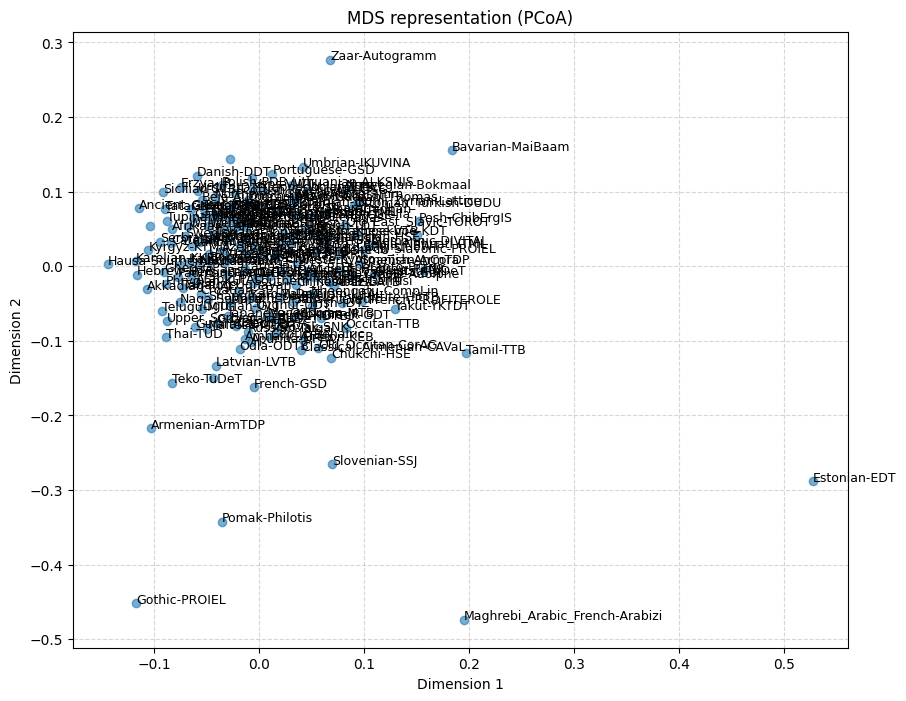

In [56]:
from sklearn.manifold import MDS
import matplotlib.pyplot as plt

# 1. Initialize MDS (MDS with 'precomputed' dissimilarity is PCoA)
mds = MDS(n_components=2, dissimilarity='precomputed', random_state=42)

# 2. Fit and transform the Gower distance matrix
coords = mds.fit_transform(distance_matrix)

# 3. Plot the results
plt.figure(figsize=(10, 8))
plt.scatter(coords[:, 0], coords[:, 1], alpha=0.6)

# Annotate each point with the language name
for i, lang_name in enumerate(pos_df.index):
    plt.annotate(lang_name, (coords[i, 0], coords[i, 1]), fontsize=9)

plt.title("MDS representation (PCoA)")
plt.xlabel("Dimension 1")
plt.ylabel("Dimension 2")
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

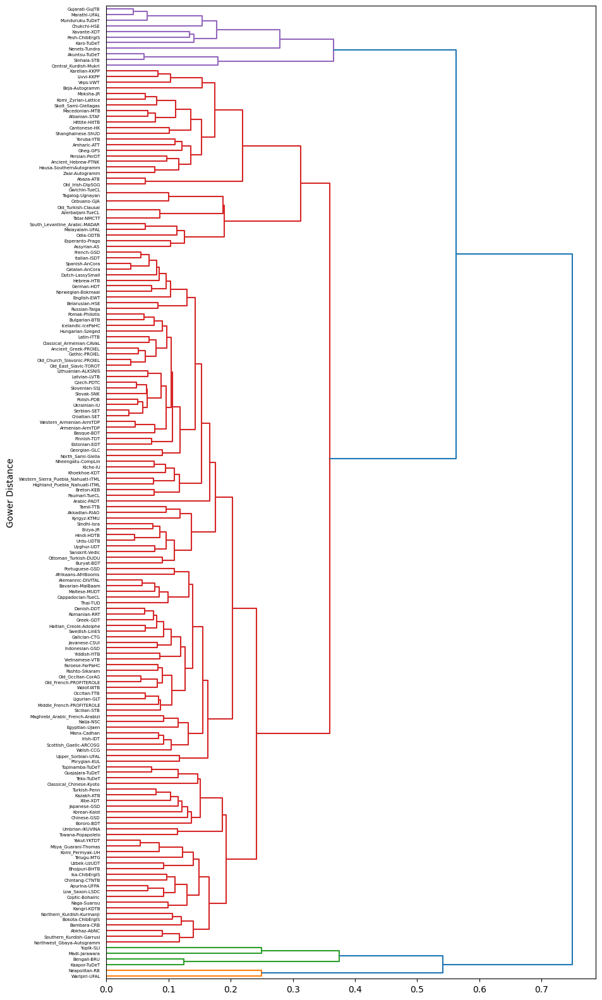

In [57]:
from scipy.cluster.hierarchy import dendrogram, linkage
from scipy.spatial.distance import squareform

# 1. Convert the distance matrix to 'condensed' form for SciPy
# (Ensures the matrix is symmetric and zeros on the diagonal)
condensed_dist = squareform(distance_matrix, force='tovector')

# 2. Perform Linkage (Ward's method is usually best for clusters)
Z = linkage(condensed_dist, method='complete')

# 3. Plot the Dendrogram
plt.figure(figsize=(10, 20))
dendrogram(Z, labels=master_df.index, leaf_rotation=0, orientation="right")
# plt.title("Hierarchical Typology of Languages")
plt.ylabel("Gower Distance")
plt.show()